In [51]:

# STEP 1: Validate the final 7-model dataset

!pip -q install openpyxl

import pandas as pd
from google.colab import files
from IPython.display import display

# Upload your final Excel file
uploaded = files.upload()

file_path = next(
    (name for name in uploaded if name.endswith(".xlsx")),
    None
)

if file_path is None:
    raise ValueError("Please upload the final .xlsx dataset.")

# Load the dataset
excel = pd.ExcelFile(file_path)
print("Available sheets:", excel.sheet_names)

sheet_name = (
    "Filtered Dataset"
    if "Filtered Dataset" in excel.sheet_names
    else excel.sheet_names[0]
)

df = pd.read_excel(file_path, sheet_name=sheet_name)

print("\nDataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

display(df.head(5))


Saving medical_anchor_bias_7B_10B.xlsx to medical_anchor_bias_7B_10B (1).xlsx
Available sheets: ['Filtered Dataset', 'Model Summary']

Dataset loaded successfully!
Rows: 2100
Columns: 11

Column names:
['question_id', 'condition', 'model', 'correct_answer', 'model_response', 'error', 'model_family', 'parameters_b', 'model_variant', 'response_blank', 'has_error']


,question_id,condition,model,correct_answer,model_response,error,model_family,parameters_b,model_variant,response_blank,has_error
0,M1,baseline,allam-2-7b,C. Severe combined immunodeficiency,C. Severe combined immunodeficiency (SCID)\n\n...,NaN,Allam 2,7.0,standard,0,0
1,M2,baseline,allam-2-7b,A. HLA-B51,"A. HLA-B51\n\nIn this patient, the most likely...",NaN,Allam 2,7.0,standard,0,0
2,M3,baseline,allam-2-7b,C. Conduct disorder,C. Conduct disorder,NaN,Allam 2,7.0,standard,0,0
3,M4,baseline,allam-2-7b,C. Actinic keratosis,A. Sporotrichosis\n\nSporotrichosis is the mos...,NaN,Allam 2,7.0,standard,0,0
4,M5,baseline,allam-2-7b,B. Cholangiocarcinoma,B. Cholangiocarcinoma,NaN,Allam 2,7.0,standard,0,0


In [52]:

# STEP 2: Model-wise data validation

import pandas as pd

required_columns = ["model", "condition"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Total rows:", len(df))
print("Unique models:", df["model"].nunique())

print("\nRows per model:")
display(df["model"].value_counts().rename("rows").to_frame())

print("\nModel-wise condition counts:")
condition_counts = pd.crosstab(
    df["model"],
    df["condition"]
)
display(condition_counts)

print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate experiment keys if question_id exists
if "question_id" in df.columns:
    duplicate_keys = df.duplicated(
        subset=["model", "question_id", "condition"],
        keep=False
    )

    print(
        "Rows involved in duplicate model-question-condition keys:",
        int(duplicate_keys.sum())
    )

# Check response blanks
response_col = next(
    (c for c in ["model_response", "raw_response"]
     if c in df.columns),
    None
)

if response_col:
    blank_mask = (
        df[response_col].isna()
        | df[response_col].astype(str).str.strip().eq("")
    )

    print("Blank responses:", int(blank_mask.sum()))

# Check API errors
if "error" in df.columns:
    errors = (
        df["error"].notna()
        & df["error"].astype(str).str.strip().ne("")
    )

    print("Rows containing errors:", int(errors.sum()))
    display(df.loc[errors, ["model", "condition", "error"]].head(20))

# Save validation tables
condition_counts.to_csv(
    "model_condition_counts.csv"
)

print("\nValidation checks completed.")


Total rows: 2100
Unique models: 7

Rows per model:


,rows
model,
allam-2-7b,300
@cf/meta/llama-3.1-8b-instruct-fast,300
@cf/mistral/mistral-7b-instruct-v0.2-lora,300
@cf/google/gemma-7b-it-lora,300
llama-3.1-8b-instruct-fp8,300
gemini-3.1-flash-lite,300
gemini-3.5-flash-lite,300



Model-wise condition counts:


condition,anchor1,anchor2,baseline
model,,,
@cf/google/gemma-7b-it-lora,100,100,100
@cf/meta/llama-3.1-8b-instruct-fast,100,100,100
@cf/mistral/mistral-7b-instruct-v0.2-lora,100,100,100
allam-2-7b,100,100,100
gemini-3.1-flash-lite,100,100,100
gemini-3.5-flash-lite,100,100,100
llama-3.1-8b-instruct-fp8,100,100,100



Duplicate rows: 0
Rows involved in duplicate model-question-condition keys: 0
Blank responses: 0
Rows containing errors: 0


,model,condition,error



Validation checks completed.


# 1.allam-2-7b

In [53]:

# FIX: ZeroDivisionError-safe accuracy calculation

summary["accuracy_pct"] = (
    summary["correct"]
    .div(summary["evaluable"].replace(0, np.nan))
    .mul(100)
    .round(2)
)

print("Accuracy summary:")
display(summary)


Accuracy summary:


,condition,total_rows,evaluable,correct,accuracy_pct,accuracy_drop_pp
0,baseline,100,95,92,96.842105,0.0
1,anchor1,100,88,77,87.5,9.342105
2,anchor2,100,85,77,90.588235,6.25387


In [54]:

print("ALLAM-2 7B — extraction diagnostic")

print("\nActual response examples:")
display(
    m[["condition", "correct_answer", "model_response"]].head(10)
)

print("\nExtracted vs missing options:")
display(
    m.groupby("condition")
     .agg(
         total_rows=("question_id", "size"),
         predicted_extracted=("predicted_option", "count"),
         correct_option_extracted=("correct_option", "count")
     )
)


ALLAM-2 7B — extraction diagnostic

Actual response examples:


,condition,correct_answer,model_response
1800,baseline,C. Severe combined immunodeficiency,C. Severe combined immunodeficiency
1801,anchor1,C. Severe combined immunodeficiency,C. Severe combined immunodeficiency
1802,anchor2,C. Severe combined immunodeficiency,C. Severe combined immunodeficiency
1803,baseline,D. Basal cell carcinoma,D. Basal cell carcinoma
1804,anchor1,D. Basal cell carcinoma,D. Basal cell carcinoma
1805,anchor2,D. Basal cell carcinoma,D. Basal cell carcinoma
1806,baseline,C. IgA nephropathy,C. IgA nephropathy
1807,anchor1,C. IgA nephropathy,C. IgA nephropathy
1808,anchor2,C. IgA nephropathy,C. IgA nephropathy
1809,baseline,A. Primary biliary cirrhosis,A. Primary biliary cirrhosis



Extracted vs missing options:


,total_rows,predicted_extracted,correct_option_extracted
condition,,,
anchor1,100,88,100
anchor2,100,85,100
baseline,100,95,100


In [55]:

# FIX: Extract MCQ options from "C. Answer text" format

import pandas as pd
import numpy as np
import re

def extract_option(text):
    if pd.isna(text) or not str(text).strip():
        return None

    text = str(text).strip()

    # Common response format: "C. Severe combined immunodeficiency"
    match = re.match(r"^\s*([A-D])\s*[\.\):\-]", text, re.I)
    if match:
        return match.group(1).upper()

    # Explicit answer declaration anywhere in response
    match = re.search(
        r"(?i)\b(?:final answer|correct answer|my answer|answer|option|choice)\s*[:\-]?\s*\(?([A-D])\)?(?=[\s\.\):\-]|$)",
        text
    )
    if match:
        return match.group(1).upper()

    return None


def extract_correct(text):
    if pd.isna(text):
        return None

    match = re.match(
        r"^\s*([A-D])\s*[\.\):\-]",
        str(text).strip(),
        re.I
    )
    return match.group(1).upper() if match else None


m["predicted_option"] = m["model_response"].apply(extract_option)
m["correct_option"] = m["correct_answer"].apply(extract_correct)

m["evaluable"] = (
    m["predicted_option"].notna()
    & m["correct_option"].notna()
)

m["is_correct"] = (
    m["predicted_option"] == m["correct_option"]
).where(m["evaluable"])

summary = (
    m.groupby("condition")
     .agg(
         total_rows=("question_id", "size"),
         evaluable=("evaluable", "sum"),
         correct=("is_correct", "sum")
     )
     .reindex(["baseline", "anchor1", "anchor2"])
)

summary["accuracy_pct"] = (
    summary["correct"]
    .div(summary["evaluable"].replace(0, np.nan))
    .mul(100)
    .round(2)
)

print("ALLAM-2 7B — Accuracy Summary")
display(summary)

print("\nExtraction check:")
display(
    m[[
        "question_id", "condition", "correct_answer",
        "model_response", "correct_option",
        "predicted_option", "is_correct"
    ]].head(15)
)

print("\nOptions extracted per condition:")
display(
    m.groupby("condition")
     .agg(
         total_rows=("question_id", "size"),
         predicted_options=("predicted_option", "count"),
         correct_options=("correct_option", "count")
     )
)


ALLAM-2 7B — Accuracy Summary


,total_rows,evaluable,correct,accuracy_pct
condition,,,,
baseline,100,95,92,96.842105
anchor1,100,88,77,87.5
anchor2,100,85,77,90.588235



Extraction check:


,question_id,condition,correct_answer,model_response,correct_option,predicted_option,is_correct
1800,M1,baseline,C. Severe combined immunodeficiency,C. Severe combined immunodeficiency,C,C,True
1801,M1,anchor1,C. Severe combined immunodeficiency,C. Severe combined immunodeficiency,C,C,True
1802,M1,anchor2,C. Severe combined immunodeficiency,C. Severe combined immunodeficiency,C,C,True
1803,M10,baseline,D. Basal cell carcinoma,D. Basal cell carcinoma,D,D,True
1804,M10,anchor1,D. Basal cell carcinoma,D. Basal cell carcinoma,D,D,True
1805,M10,anchor2,D. Basal cell carcinoma,D. Basal cell carcinoma,D,D,True
1806,M100,baseline,C. IgA nephropathy,C. IgA nephropathy,C,C,True
1807,M100,anchor1,C. IgA nephropathy,C. IgA nephropathy,C,C,True
1808,M100,anchor2,C. IgA nephropathy,C. IgA nephropathy,C,C,True
1809,M11,baseline,A. Primary biliary cirrhosis,A. Primary biliary cirrhosis,A,A,True



Options extracted per condition:


,total_rows,predicted_options,correct_options
condition,,,
anchor1,100,88,100
anchor2,100,85,100
baseline,100,95,100


In [56]:

# STEP 3.1B — ALLAM-2 7B: Diagnostic flips and anchor resistance

# One row per question and condition
wide = m.pivot_table(
    index="question_id",
    columns="condition",
    values="is_correct",
    aggfunc="first"
)

results = []

for anchor in ["anchor1", "anchor2"]:
    paired = wide[["baseline", anchor]].dropna()

    baseline_correct_anchor_wrong = (
        (paired["baseline"] == True) &
        (paired[anchor] == False)
    ).sum()

    baseline_wrong_anchor_correct = (
        (paired["baseline"] == False) &
        (paired[anchor] == True)
    ).sum()

    correct_both = (
        (paired["baseline"] == True) &
        (paired[anchor] == True)
    ).sum()

    wrong_both = (
        (paired["baseline"] == False) &
        (paired[anchor] == False)
    ).sum()

    results.append({
        "anchor_condition": anchor,
        "paired_questions": len(paired),
        "baseline_correct_anchor_wrong": int(baseline_correct_anchor_wrong),
        "baseline_wrong_anchor_correct": int(baseline_wrong_anchor_correct),
        "correct_in_both": int(correct_both),
        "wrong_in_both": int(wrong_both)
    })

flip_results = pd.DataFrame(results)

print("ALLAM-2 7B — Paired correctness transitions")
display(flip_results)

# Save this model's analysis data for reproducibility
m.to_csv("allam_2_7b_analysis.csv", index=False)
flip_results.to_csv("allam_2_7b_transition_results.csv", index=False)

print("Saved: allam_2_7b_analysis.csv")
print("Saved: allam_2_7b_transition_results.csv")


ALLAM-2 7B — Paired correctness transitions


,anchor_condition,paired_questions,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both
0,anchor1,84,7,1,74,2
1,anchor2,81,5,1,74,1


Saved: allam_2_7b_analysis.csv
Saved: allam_2_7b_transition_results.csv


# 2.@cf/meta/llama-3.1-8b models

In [57]:

MODEL = "@cf/meta/llama-3.1-8b-instruct-fast"

m = df[df["model"].astype(str).str.strip() == MODEL].copy()
m["condition"] = m["condition"].astype(str).str.strip().str.lower()

print("Model:", MODEL)
print("\nRows by condition:")
print(m["condition"].value_counts())

print("\nBlank responses:", m["model_response"].isna().sum())
print("Error rows:", m["has_error"].astype(str).str.lower().isin(["true", "1"]).sum())


Model: @cf/meta/llama-3.1-8b-instruct-fast

Rows by condition:
condition
baseline    100
anchor1     100
anchor2     100
Name: count, dtype: int64

Blank responses: 0
Error rows: 0


In [58]:

m["predicted_option"] = m["model_response"].apply(extract_option)
m["correct_option"] = m["correct_answer"].apply(extract_correct)

m["evaluable"] = (
    m["predicted_option"].notna()
    & m["correct_option"].notna()
)

m["is_correct"] = (
    m["predicted_option"] == m["correct_option"]
).where(m["evaluable"])

summary = (
    m.groupby("condition")
    .agg(
        total_rows=("question_id", "size"),
        evaluable=("evaluable", "sum"),
        correct=("is_correct", "sum")
    )
    .reset_index()
)

summary["accuracy_pct"] = (
    100 * summary["correct"] / summary["evaluable"].replace(0, np.nan)
)

display(summary)


,condition,total_rows,evaluable,correct,accuracy_pct
0,anchor1,100,100,56,56.0
1,anchor2,100,100,49,49.0
2,baseline,100,100,93,93.0


In [59]:

wide = m.pivot_table(
    index="question_id",
    columns="condition",
    values="is_correct",
    aggfunc="first"
)

results = []

for anchor in ["anchor1", "anchor2"]:
    paired = wide[["baseline", anchor]].dropna()

    results.append({
        "anchor_condition": anchor,
        "paired_questions": len(paired),
        "baseline_correct_anchor_wrong": (
            (paired["baseline"] == True) &
            (paired[anchor] == False)
        ).sum(),
        "baseline_wrong_anchor_correct": (
            (paired["baseline"] == False) &
            (paired[anchor] == True)
        ).sum(),
        "correct_in_both": (
            (paired["baseline"] == True) &
            (paired[anchor] == True)
        ).sum(),
        "wrong_in_both": (
            (paired["baseline"] == False) &
            (paired[anchor] == False)
        ).sum()
    })

flip_results = pd.DataFrame(results)
display(flip_results)

m.to_csv("llama_3_1_8b_fast_analysis.csv", index=False)
flip_results.to_csv(
    "llama_3_1_8b_fast_transition_results.csv",
    index=False
)

print("Saved both analysis CSV files.")


,anchor_condition,paired_questions,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both
0,anchor1,100,38,1,55,6
1,anchor2,100,45,1,48,6


Saved both analysis CSV files.


# 3.Mistral 7B Instruct v0.2 LoRA

In [60]:

import pandas as pd
import numpy as np
import re

# ==================================================
# MODEL 3: MISTRAL 7B INSTRUCT v0.2 LoRA
# ==================================================
MODEL = "@cf/mistral/mistral-7b-instruct-v0.2-lora"

m = df[df["model"].astype(str).str.strip() == MODEL].copy()
m["condition"] = m["condition"].astype(str).str.strip().str.lower()

if m.empty:
    raise ValueError(f"Model not found in dataset: {MODEL}")

# 1. Extract predicted answer option
def extract_option(text):
    if pd.isna(text) or not str(text).strip():
        return None

    text = str(text).strip()

    match = re.match(r"^\s*([A-D])\s*[\.\):\-]", text, re.I)
    if match:
        return match.group(1).upper()

    match = re.search(
        r"(?i)\b(?:final answer|correct answer|my answer|answer|option|choice)"
        r"\s*[:\-]?\s*\(?([A-D])\)?(?=[\s\.\):\-]|$)",
        text
    )
    return match.group(1).upper() if match else None

# 2. Extract correct answer option
def extract_correct(text):
    if pd.isna(text):
        return None

    match = re.match(
        r"^\s*([A-D])\s*[\.\):\-]",
        str(text).strip(),
        re.I
    )
    return match.group(1).upper() if match else None

m["predicted_option"] = m["model_response"].apply(extract_option)
m["correct_option"] = m["correct_answer"].apply(extract_correct)

m["evaluable"] = (
    m["predicted_option"].notna()
    & m["correct_option"].notna()
)

m["is_correct"] = (
    m["predicted_option"] == m["correct_option"]
).where(m["evaluable"])

# 3. Dataset quality check
print("=" * 65)
print("MODEL:", MODEL)
print("\nRows per condition:")
print(m["condition"].value_counts().reindex(
    ["baseline", "anchor1", "anchor2"], fill_value=0
))
print("\nBlank responses:", m["model_response"].isna().sum()
      + (m["model_response"].astype(str).str.strip() == "").sum())
print("Error rows:", (
    m["has_error"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"]).sum()
    if "has_error" in m.columns else "Column unavailable"
))

# 4. Accuracy and accuracy drop
summary = (
    m.groupby("condition")
    .agg(
        total_rows=("question_id", "size"),
        evaluable=("evaluable", "sum"),
        correct=("is_correct", "sum")
    )
    .reindex(["baseline", "anchor1", "anchor2"])
    .reset_index()
)

summary["accuracy_pct"] = (
    100 * summary["correct"]
    / summary["evaluable"].replace(0, np.nan)
)

baseline_acc = summary.loc[
    summary["condition"] == "baseline", "accuracy_pct"
].iloc[0]

summary["accuracy_drop_pp"] = (
    baseline_acc - summary["accuracy_pct"]
)

# 5. Paired transitions and anchor resistance
wide = m.pivot_table(
    index="question_id",
    columns="condition",
    values="is_correct",
    aggfunc="first"
)

transition_rows = []

for anchor in ["anchor1", "anchor2"]:
    paired = wide[["baseline", anchor]].dropna()

    baseline_correct = paired["baseline"].eq(True)
    anchor_correct = paired[anchor].eq(True)

    transition_rows.append({
        "anchor_condition": anchor,
        "paired_questions": len(paired),
        "baseline_correct_anchor_wrong": int(
            (baseline_correct & ~anchor_correct).sum()
        ),
        "baseline_wrong_anchor_correct": int(
            (~baseline_correct & anchor_correct).sum()
        ),
        "correct_in_both": int(
            (baseline_correct & anchor_correct).sum()
        ),
        "wrong_in_both": int(
            (~baseline_correct & ~anchor_correct).sum()
        ),
        "anchor_resistance_pct": (
            100 * (baseline_correct & anchor_correct).sum()
            / baseline_correct.sum()
            if baseline_correct.sum() else np.nan
        )
    })

transitions = pd.DataFrame(transition_rows)

# 6. Display results
print("\n" + "=" * 65)
print("ACCURACY RESULTS")
display(summary.round(2))

print("\nPAIRED TRANSITION RESULTS")
display(transitions.round(2))

# 7. Save outputs
m.to_csv("mistral_7b_analysis.csv", index=False)
summary.to_csv("mistral_7b_accuracy.csv", index=False)
transitions.to_csv("mistral_7b_transitions.csv", index=False)

print("\nSaved:")
print("- mistral_7b_analysis.csv")
print("- mistral_7b_accuracy.csv")
print("- mistral_7b_transitions.csv")

print("\nNote: Anchor-following and harmful anchoring require")
print("the actual anchor target for each question.")


MODEL: @cf/mistral/mistral-7b-instruct-v0.2-lora

Rows per condition:
condition
baseline    100
anchor1     100
anchor2     100
Name: count, dtype: int64

Blank responses: 0
Error rows: 0

ACCURACY RESULTS


,condition,total_rows,evaluable,correct,accuracy_pct,accuracy_drop_pp
0,baseline,100,96,47,48.958333,0.0
1,anchor1,100,100,27,27.0,21.958333
2,anchor2,100,96,21,21.875,27.083333



PAIRED TRANSITION RESULTS


,anchor_condition,paired_questions,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both,anchor_resistance_pct
0,anchor1,96,21,1,26,48,55.32
1,anchor2,92,24,0,21,47,46.67



Saved:
- mistral_7b_analysis.csv
- mistral_7b_accuracy.csv
- mistral_7b_transitions.csv

Note: Anchor-following and harmful anchoring require
the actual anchor target for each question.


# 4 — Gemma 7B IT LoRA

In [61]:

import pandas as pd
import numpy as np
import re

# ==================================================
# MODEL 4: GEMMA 7B IT LoRA
# ==================================================
MODEL = "@cf/google/gemma-7b-it-lora"

m = df[df["model"].astype(str).str.strip() == MODEL].copy()
m["condition"] = m["condition"].astype(str).str.strip().str.lower()

if m.empty:
    raise ValueError(f"Model not found: {MODEL}")

def extract_option(text):
    if pd.isna(text) or not str(text).strip():
        return None

    text = str(text).strip()

    match = re.match(r"^\s*([A-D])\s*[\.\):\-]", text, re.I)
    if match:
        return match.group(1).upper()

    match = re.search(
        r"(?i)\b(?:final answer|correct answer|my answer|answer|option|choice)"
        r"\s*[:\-]?\s*\(?([A-D])\)?(?=[\s\.\):\-]|$)",
        text
    )
    return match.group(1).upper() if match else None

def extract_correct(text):
    if pd.isna(text):
        return None

    match = re.match(
        r"^\s*([A-D])\s*[\.\):\-]",
        str(text).strip(),
        re.I
    )
    return match.group(1).upper() if match else None

# Extract answers
m["predicted_option"] = m["model_response"].apply(extract_option)
m["correct_option"] = m["correct_answer"].apply(extract_correct)

m["evaluable"] = (
    m["predicted_option"].notna()
    & m["correct_option"].notna()
)

m["is_correct"] = (
    m["predicted_option"] == m["correct_option"]
).where(m["evaluable"])

# Dataset checks
print("=" * 65)
print("MODEL:", MODEL)
print("\nRows per condition:")
print(m["condition"].value_counts().reindex(
    ["baseline", "anchor1", "anchor2"], fill_value=0
))
print("\nBlank responses:", (
    m["model_response"].isna()
    | m["model_response"].astype(str).str.strip().eq("")
).sum())
print("Error rows:", (
    m["has_error"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"]).sum()
    if "has_error" in m.columns else "Column unavailable"
))

# Accuracy and drop
summary = (
    m.groupby("condition")
    .agg(
        total_rows=("question_id", "size"),
        evaluable=("evaluable", "sum"),
        correct=("is_correct", "sum")
    )
    .reindex(["baseline", "anchor1", "anchor2"])
    .reset_index()
)

summary["accuracy_pct"] = (
    100 * summary["correct"]
    / summary["evaluable"].replace(0, np.nan)
)

baseline_acc = summary.loc[
    summary["condition"] == "baseline", "accuracy_pct"
].iloc[0]

summary["accuracy_drop_pp"] = baseline_acc - summary["accuracy_pct"]

# Paired transitions and anchor resistance
wide = m.pivot_table(
    index="question_id",
    columns="condition",
    values="is_correct",
    aggfunc="first"
)

transition_rows = []

for anchor in ["anchor1", "anchor2"]:
    paired = wide[["baseline", anchor]].dropna()

    base_correct = paired["baseline"].eq(True)
    anchor_correct = paired[anchor].eq(True)

    transition_rows.append({
        "anchor_condition": anchor,
        "paired_questions": len(paired),
        "baseline_correct_anchor_wrong": int(
            (base_correct & ~anchor_correct).sum()
        ),
        "baseline_wrong_anchor_correct": int(
            (~base_correct & anchor_correct).sum()
        ),
        "correct_in_both": int(
            (base_correct & anchor_correct).sum()
        ),
        "wrong_in_both": int(
            (~base_correct & ~anchor_correct).sum()
        ),
        "anchor_resistance_pct": (
            100 * (base_correct & anchor_correct).sum()
            / base_correct.sum()
            if base_correct.sum() else np.nan
        )
    })

transitions = pd.DataFrame(transition_rows)

# Display
print("\nACCURACY RESULTS")
display(summary.round(2))

print("\nPAIRED TRANSITION RESULTS")
display(transitions.round(2))

# Save outputs
m.to_csv("gemma_7b_analysis.csv", index=False)
summary.to_csv("gemma_7b_accuracy.csv", index=False)
transitions.to_csv("gemma_7b_transitions.csv", index=False)

print("\nSaved:")
print("- gemma_7b_analysis.csv")
print("- gemma_7b_accuracy.csv")
print("- gemma_7b_transitions.csv")

print("\nNote: Direct anchor-following and harmful-anchoring")
print("metrics require the actual anchor target for each question.")


MODEL: @cf/google/gemma-7b-it-lora

Rows per condition:
condition
baseline    100
anchor1     100
anchor2     100
Name: count, dtype: int64

Blank responses: 0
Error rows: 0

ACCURACY RESULTS


,condition,total_rows,evaluable,correct,accuracy_pct,accuracy_drop_pp
0,baseline,100,99,65,65.656566,0.0
1,anchor1,100,100,11,11.0,54.656566
2,anchor2,100,100,9,9.0,56.656566



PAIRED TRANSITION RESULTS


,anchor_condition,paired_questions,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both,anchor_resistance_pct
0,anchor1,99,55,0,10,34,15.38
1,anchor2,99,56,0,9,34,13.85



Saved:
- gemma_7b_analysis.csv
- gemma_7b_accuracy.csv
- gemma_7b_transitions.csv

Note: Direct anchor-following and harmful-anchoring
metrics require the actual anchor target for each question.


# 5 — Llama 3.1 8B Instruct FP8

In [62]:

import pandas as pd
import numpy as np
import re

# ==================================================
# MODEL 5: LLAMA 3.1 8B INSTRUCT FP8
# ==================================================
MODEL = "llama-3.1-8b-instruct-fp8"

m = df[df["model"].astype(str).str.strip() == MODEL].copy()
m["condition"] = m["condition"].astype(str).str.strip().str.lower()

if m.empty:
    raise ValueError(f"Model not found: {MODEL}")

def extract_option(text):
    if pd.isna(text) or not str(text).strip():
        return None

    text = str(text).strip()

    match = re.match(r"^\s*([A-D])\s*[\.\):\-]", text, re.I)
    if match:
        return match.group(1).upper()

    match = re.search(
        r"(?i)\b(?:final answer|correct answer|my answer|answer|option|choice)"
        r"\s*[:\-]?\s*\(?([A-D])\)?(?=[\s\.\):\-]|$)",
        text
    )
    return match.group(1).upper() if match else None

def extract_correct(text):
    if pd.isna(text):
        return None

    match = re.match(
        r"^\s*([A-D])\s*[\.\):\-]",
        str(text).strip(),
        re.I
    )
    return match.group(1).upper() if match else None

# Extract answers
m["predicted_option"] = m["model_response"].apply(extract_option)
m["correct_option"] = m["correct_answer"].apply(extract_correct)

m["evaluable"] = (
    m["predicted_option"].notna()
    & m["correct_option"].notna()
)

m["is_correct"] = (
    m["predicted_option"] == m["correct_option"]
).where(m["evaluable"])

# Dataset checks
print("=" * 65)
print("MODEL:", MODEL)
print("\nRows per condition:")
print(m["condition"].value_counts().reindex(
    ["baseline", "anchor1", "anchor2"], fill_value=0
))

print("\nBlank responses:", (
    m["model_response"].isna()
    | m["model_response"].astype(str).str.strip().eq("")
).sum())

print("Error rows:", (
    m["has_error"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"]).sum()
    if "has_error" in m.columns else "Column unavailable"
))

# Accuracy and accuracy drop
summary = (
    m.groupby("condition")
    .agg(
        total_rows=("question_id", "size"),
        evaluable=("evaluable", "sum"),
        correct=("is_correct", "sum")
    )
    .reindex(["baseline", "anchor1", "anchor2"])
    .reset_index()
)

summary["accuracy_pct"] = (
    100 * summary["correct"]
    / summary["evaluable"].replace(0, np.nan)
)

baseline_acc = summary.loc[
    summary["condition"] == "baseline", "accuracy_pct"
].iloc[0]

summary["accuracy_drop_pp"] = (
    baseline_acc - summary["accuracy_pct"]
)

# Paired transitions and anchor resistance
wide = m.pivot_table(
    index="question_id",
    columns="condition",
    values="is_correct",
    aggfunc="first"
)

transition_rows = []

for anchor in ["anchor1", "anchor2"]:
    paired = wide[["baseline", anchor]].dropna()

    base_correct = paired["baseline"].eq(True)
    anchor_correct = paired[anchor].eq(True)

    transition_rows.append({
        "anchor_condition": anchor,
        "paired_questions": len(paired),
        "baseline_correct_anchor_wrong": int(
            (base_correct & ~anchor_correct).sum()
        ),
        "baseline_wrong_anchor_correct": int(
            (~base_correct & anchor_correct).sum()
        ),
        "correct_in_both": int(
            (base_correct & anchor_correct).sum()
        ),
        "wrong_in_both": int(
            (~base_correct & ~anchor_correct).sum()
        ),
        "anchor_resistance_pct": (
            100 * (base_correct & anchor_correct).sum()
            / base_correct.sum()
            if base_correct.sum() else np.nan
        )
    })

transitions = pd.DataFrame(transition_rows)

# Display
print("\nACCURACY RESULTS")
display(summary.round(2))

print("\nPAIRED TRANSITION RESULTS")
display(transitions.round(2))

# Save outputs
m.to_csv("llama_3_1_8b_fp8_analysis.csv", index=False)
summary.to_csv("llama_3_1_8b_fp8_accuracy.csv", index=False)
transitions.to_csv("llama_3_1_8b_fp8_transitions.csv", index=False)

print("\nSaved:")
print("- llama_3_1_8b_fp8_analysis.csv")
print("- llama_3_1_8b_fp8_accuracy.csv")
print("- llama_3_1_8b_fp8_transitions.csv")


MODEL: llama-3.1-8b-instruct-fp8

Rows per condition:
condition
baseline    100
anchor1     100
anchor2     100
Name: count, dtype: int64

Blank responses: 0
Error rows: 0

ACCURACY RESULTS


,condition,total_rows,evaluable,correct,accuracy_pct,accuracy_drop_pp
0,baseline,100,100,87,87.0,0.0
1,anchor1,100,100,55,55.0,32.0
2,anchor2,100,97,52,53.608247,33.391753



PAIRED TRANSITION RESULTS


,anchor_condition,paired_questions,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both,anchor_resistance_pct
0,anchor1,100,33,1,54,12,62.07
1,anchor2,97,36,3,49,9,57.65



Saved:
- llama_3_1_8b_fp8_analysis.csv
- llama_3_1_8b_fp8_accuracy.csv
- llama_3_1_8b_fp8_transitions.csv


# 6 — Gemini 3.1 Flash Lite

In [63]:

import pandas as pd
import numpy as np
import re

# ==================================================
# MODEL 6: GEMINI 3.1 FLASH LITE
# ==================================================
MODEL = "gemini-3.1-flash-lite"

m = df[df["model"].astype(str).str.strip() == MODEL].copy()
m["condition"] = m["condition"].astype(str).str.strip().str.lower()

if m.empty:
    raise ValueError(f"Model not found: {MODEL}")

def extract_option(text):
    if pd.isna(text) or not str(text).strip():
        return None

    text = str(text).strip()

    match = re.match(r"^\s*([A-D])\s*[\.\):\-]", text, re.I)
    if match:
        return match.group(1).upper()

    match = re.search(
        r"(?i)\b(?:final answer|correct answer|my answer|answer|option|choice)"
        r"\s*[:\-]?\s*\(?([A-D])\)?(?=[\s\.\):\-]|$)",
        text
    )
    return match.group(1).upper() if match else None

def extract_correct(text):
    if pd.isna(text):
        return None

    match = re.match(
        r"^\s*([A-D])\s*[\.\):\-]",
        str(text).strip(),
        re.I
    )
    return match.group(1).upper() if match else None

# Extract answers
m["predicted_option"] = m["model_response"].apply(extract_option)
m["correct_option"] = m["correct_answer"].apply(extract_correct)

m["evaluable"] = (
    m["predicted_option"].notna()
    & m["correct_option"].notna()
)

m["is_correct"] = (
    m["predicted_option"] == m["correct_option"]
).where(m["evaluable"])

# Dataset checks
print("=" * 65)
print("MODEL:", MODEL)
print("\nRows per condition:")
print(m["condition"].value_counts().reindex(
    ["baseline", "anchor1", "anchor2"], fill_value=0
))

print("\nBlank responses:", (
    m["model_response"].isna()
    | m["model_response"].astype(str).str.strip().eq("")
).sum())

print("Error rows:", (
    m["has_error"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"]).sum()
    if "has_error" in m.columns else "Column unavailable"
))

# Accuracy and drop
summary = (
    m.groupby("condition")
    .agg(
        total_rows=("question_id", "size"),
        evaluable=("evaluable", "sum"),
        correct=("is_correct", "sum")
    )
    .reindex(["baseline", "anchor1", "anchor2"])
    .reset_index()
)

summary["accuracy_pct"] = (
    100 * summary["correct"]
    / summary["evaluable"].replace(0, np.nan)
)

baseline_acc = summary.loc[
    summary["condition"] == "baseline", "accuracy_pct"
].iloc[0]

summary["accuracy_drop_pp"] = (
    baseline_acc - summary["accuracy_pct"]
)

# Paired transitions and resistance
wide = m.pivot_table(
    index="question_id",
    columns="condition",
    values="is_correct",
    aggfunc="first"
)

transition_rows = []

for anchor in ["anchor1", "anchor2"]:
    paired = wide[["baseline", anchor]].dropna()

    base_correct = paired["baseline"].eq(True)
    anchor_correct = paired[anchor].eq(True)

    transition_rows.append({
        "anchor_condition": anchor,
        "paired_questions": len(paired),
        "baseline_correct_anchor_wrong": int(
            (base_correct & ~anchor_correct).sum()
        ),
        "baseline_wrong_anchor_correct": int(
            (~base_correct & anchor_correct).sum()
        ),
        "correct_in_both": int(
            (base_correct & anchor_correct).sum()
        ),
        "wrong_in_both": int(
            (~base_correct & ~anchor_correct).sum()
        ),
        "anchor_resistance_pct": (
            100 * (base_correct & anchor_correct).sum()
            / base_correct.sum()
            if base_correct.sum() else np.nan
        )
    })

transitions = pd.DataFrame(transition_rows)

# Display results
print("\nACCURACY RESULTS")
display(summary.round(2))

print("\nPAIRED TRANSITION RESULTS")
display(transitions.round(2))

# Save outputs
m.to_csv("gemini_3_1_flash_lite_analysis.csv", index=False)
summary.to_csv("gemini_3_1_flash_lite_accuracy.csv", index=False)
transitions.to_csv("gemini_3_1_flash_lite_transitions.csv", index=False)

print("\nSaved:")
print("- gemini_3_1_flash_lite_analysis.csv")
print("- gemini_3_1_flash_lite_accuracy.csv")
print("- gemini_3_1_flash_lite_transitions.csv")


MODEL: gemini-3.1-flash-lite

Rows per condition:
condition
baseline    100
anchor1     100
anchor2     100
Name: count, dtype: int64

Blank responses: 0
Error rows: 0

ACCURACY RESULTS


,condition,total_rows,evaluable,correct,accuracy_pct,accuracy_drop_pp
0,baseline,100,99,98,98.989899,0.0
1,anchor1,100,100,95,95.0,3.989899
2,anchor2,100,100,91,91.0,7.989899



PAIRED TRANSITION RESULTS


,anchor_condition,paired_questions,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both,anchor_resistance_pct
0,anchor1,99,3,0,95,1,96.94
1,anchor2,99,7,0,91,1,92.86



Saved:
- gemini_3_1_flash_lite_analysis.csv
- gemini_3_1_flash_lite_accuracy.csv
- gemini_3_1_flash_lite_transitions.csv


# 7 — Gemini 3.5 Flash Lite

In [64]:

import pandas as pd
import numpy as np
import re

# ==================================================
# MODEL 7: GEMINI 3.5 FLASH LITE
# ==================================================
MODEL = "gemini-3.5-flash-lite"

m = df[df["model"].astype(str).str.strip() == MODEL].copy()
m["condition"] = m["condition"].astype(str).str.strip().str.lower()

if m.empty:
    raise ValueError(f"Model not found: {MODEL}")

def extract_option(text):
    if pd.isna(text) or not str(text).strip():
        return None

    text = str(text).strip()

    match = re.match(r"^\s*([A-D])\s*[\.\):\-]", text, re.I)
    if match:
        return match.group(1).upper()

    match = re.search(
        r"(?i)\b(?:final answer|correct answer|my answer|answer|option|choice)"
        r"\s*[:\-]?\s*\(?([A-D])\)?(?=[\s\.\):\-]|$)",
        text
    )
    return match.group(1).upper() if match else None

def extract_correct(text):
    if pd.isna(text):
        return None

    match = re.match(
        r"^\s*([A-D])\s*[\.\):\-]",
        str(text).strip(),
        re.I
    )
    return match.group(1).upper() if match else None

# Extract answers
m["predicted_option"] = m["model_response"].apply(extract_option)
m["correct_option"] = m["correct_answer"].apply(extract_correct)

m["evaluable"] = (
    m["predicted_option"].notna()
    & m["correct_option"].notna()
)

m["is_correct"] = (
    m["predicted_option"] == m["correct_option"]
).where(m["evaluable"])

# Dataset checks
print("=" * 65)
print("MODEL:", MODEL)
print("\nRows per condition:")
print(m["condition"].value_counts().reindex(
    ["baseline", "anchor1", "anchor2"], fill_value=0
))

print("\nBlank responses:", (
    m["model_response"].isna()
    | m["model_response"].astype(str).str.strip().eq("")
).sum())

print("Error rows:", (
    m["has_error"].astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"]).sum()
    if "has_error" in m.columns else "Column unavailable"
))

# Accuracy and drop
summary = (
    m.groupby("condition")
    .agg(
        total_rows=("question_id", "size"),
        evaluable=("evaluable", "sum"),
        correct=("is_correct", "sum")
    )
    .reindex(["baseline", "anchor1", "anchor2"])
    .reset_index()
)

summary["accuracy_pct"] = (
    100 * summary["correct"]
    / summary["evaluable"].replace(0, np.nan)
)

baseline_acc = summary.loc[
    summary["condition"] == "baseline", "accuracy_pct"
].iloc[0]

summary["accuracy_drop_pp"] = (
    baseline_acc - summary["accuracy_pct"]
)

# Paired transitions and resistance
wide = m.pivot_table(
    index="question_id",
    columns="condition",
    values="is_correct",
    aggfunc="first"
)

transition_rows = []

for anchor in ["anchor1", "anchor2"]:
    paired = wide[["baseline", anchor]].dropna()

    base_correct = paired["baseline"].eq(True)
    anchor_correct = paired[anchor].eq(True)

    transition_rows.append({
        "anchor_condition": anchor,
        "paired_questions": len(paired),
        "baseline_correct_anchor_wrong": int(
            (base_correct & ~anchor_correct).sum()
        ),
        "baseline_wrong_anchor_correct": int(
            (~base_correct & anchor_correct).sum()
        ),
        "correct_in_both": int(
            (base_correct & anchor_correct).sum()
        ),
        "wrong_in_both": int(
            (~base_correct & ~anchor_correct).sum()
        ),
        "anchor_resistance_pct": (
            100 * (base_correct & anchor_correct).sum()
            / base_correct.sum()
            if base_correct.sum() else np.nan
        )
    })

transitions = pd.DataFrame(transition_rows)

# Display results
print("\nACCURACY RESULTS")
display(summary.round(2))

print("\nPAIRED TRANSITION RESULTS")
display(transitions.round(2))

# Save outputs
m.to_csv("gemini_3_5_flash_lite_analysis.csv", index=False)
summary.to_csv("gemini_3_5_flash_lite_accuracy.csv", index=False)
transitions.to_csv("gemini_3_5_flash_lite_transitions.csv", index=False)

print("\nSaved:")
print("- gemini_3_5_flash_lite_analysis.csv")
print("- gemini_3_5_flash_lite_accuracy.csv")
print("- gemini_3_5_flash_lite_transitions.csv")


MODEL: gemini-3.5-flash-lite

Rows per condition:
condition
baseline    100
anchor1     100
anchor2     100
Name: count, dtype: int64

Blank responses: 0
Error rows: 0

ACCURACY RESULTS


,condition,total_rows,evaluable,correct,accuracy_pct,accuracy_drop_pp
0,baseline,100,95,92,96.842105,0.0
1,anchor1,100,88,77,87.5,9.342105
2,anchor2,100,85,77,90.588235,6.25387



PAIRED TRANSITION RESULTS


,anchor_condition,paired_questions,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both,anchor_resistance_pct
0,anchor1,84,7,1,74,2,91.36
1,anchor2,81,5,1,74,1,93.67



Saved:
- gemini_3_5_flash_lite_analysis.csv
- gemini_3_5_flash_lite_accuracy.csv
- gemini_3_5_flash_lite_transitions.csv


# using 7 models

In [68]:
# STEP 4A: CROSS-MODEL MASTER COMPARISON + STATISTICAL TESTS

import pandas as pd
import numpy as np
import re
from scipy.stats import binomtest
from IPython.display import display

# 1. Validate source data
required = [
    "model", "question_id", "condition",
    "correct_answer", "model_response"
]

missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns in df: {missing}")

data = df.copy()
data["model"] = data["model"].astype(str).str.strip()
data["condition"] = (
    data["condition"].astype(str).str.strip().str.lower()
)

# 2. Robust option extraction
def extract_option(text):
    if pd.isna(text) or not str(text).strip():
        return None

    text = re.sub(r"[*_`#]", "", str(text).strip())

    patterns = [
        r"(?im)^\s*(?:final answer|correct answer|my answer|answer|option|choice)\s*[:\-]\s*\(?([A-D])\)?(?:\b|$)",
        r"(?im)^\s*\(?([A-D])\)?\s*[.)\-:]\s+",
        r"(?i)\b(?:the correct answer is|my answer is|answer is)\s+\(?([A-D])\)?\b",
        r"^\s*\(?([A-D])\)?(?:\s|$)"
    ]

    for pattern in patterns:
        match = re.search(pattern, text)
        if match:
            return match.group(1).upper()

    return None


def extract_correct(text):
    if pd.isna(text):
        return None

    text = re.sub(r"[*_`#]", "", str(text).strip())

    match = re.match(
        r"^\s*\(?([A-D])\)?(?:[.)\s:\-]|$)",
        text,
        re.I
    )

    return match.group(1).upper() if match else None


data["predicted_option"] = data["model_response"].apply(extract_option)
data["correct_option"] = data["correct_answer"].apply(extract_correct)

data["evaluable"] = (
    data["predicted_option"].notna()
    & data["correct_option"].notna()
)

data["is_correct"] = np.nan
valid = data["evaluable"]

data.loc[valid, "is_correct"] = (
    data.loc[valid, "predicted_option"]
    == data.loc[valid, "correct_option"]
).astype(int)

# 3. Confirm model/condition coverage
print("MODEL COUNT:", data["model"].nunique())
print("MODEL NAMES:", sorted(data["model"].unique()))

display(pd.crosstab(data["model"], data["condition"]))

if data["model"].nunique() != 7:
    raise ValueError("Expected 7 models. Verify the loaded source dataset.")

expected = {"baseline", "anchor1", "anchor2"}
if not expected.issubset(set(data["condition"].unique())):
    raise ValueError("Expected conditions: baseline, anchor1, anchor2.")

# Check duplicate model-question-condition records
duplicates = data.duplicated(
    ["model", "question_id", "condition"],
    keep=False
)

print("Duplicate model-question-condition rows:", int(duplicates.sum()))

if duplicates.any():
    raise ValueError("Duplicates found; resolve them before paired tests.")

# 4. Model accuracy table
accuracy_rows = []

for model in sorted(data["model"].unique()):
    m = data[data["model"] == model]
    row = {"model": model}

    for cond in ["baseline", "anchor1", "anchor2"]:
        s = m[(m["condition"] == cond) & m["evaluable"]]

        row[f"{cond}_n"] = len(s)
        row[f"{cond}_correct"] = int(s["is_correct"].sum())
        row[f"{cond}_accuracy_pct"] = (
            100 * s["is_correct"].mean() if len(s) else np.nan
        )

    row["anchor1_drop_pp"] = (
        row["baseline_accuracy_pct"] - row["anchor1_accuracy_pct"]
    )
    row["anchor2_drop_pp"] = (
        row["baseline_accuracy_pct"] - row["anchor2_accuracy_pct"]
    )

    accuracy_rows.append(row)

accuracy_table = pd.DataFrame(accuracy_rows)

# 5. Paired transitions + exact McNemar-equivalent test
paired_rows = []

for model in sorted(data["model"].unique()):
    m = data[data["model"] == model]

    baseline = m[
        (m["condition"] == "baseline") & m["evaluable"]
    ][["question_id", "is_correct"]].rename(
        columns={"is_correct": "baseline_correct"}
    )

    for anchor in ["anchor1", "anchor2"]:
        anchored = m[
            (m["condition"] == anchor) & m["evaluable"]
        ][["question_id", "is_correct"]].rename(
            columns={"is_correct": "anchor_correct"}
        )

        paired = baseline.merge(
            anchored,
            on="question_id",
            how="inner",
            validate="one_to_one"
        )

        b = paired["baseline_correct"].astype(bool)
        a = paired["anchor_correct"].astype(bool)

        correct_to_wrong = int((b & ~a).sum())
        wrong_to_correct = int((~b & a).sum())
        correct_both = int((b & a).sum())
        wrong_both = int((~b & ~a).sum())

        baseline_correct_n = correct_to_wrong + correct_both
        discordant = correct_to_wrong + wrong_to_correct

        resistance = (
            100 * correct_both / baseline_correct_n
            if baseline_correct_n else np.nan
        )

        p = (
            binomtest(
                correct_to_wrong,
                n=discordant,
                p=0.5,
                alternative="two-sided"
            ).pvalue
            if discordant else 1.0
        )

        paired_rows.append({
            "model": model,
            "anchor": anchor,
            "paired_n": len(paired),
            "baseline_correct_anchor_wrong": correct_to_wrong,
            "baseline_wrong_anchor_correct": wrong_to_correct,
            "correct_in_both": correct_both,
            "wrong_in_both": wrong_both,
            "anchor_resistance_pct": resistance,
            "exact_p_value": p
        })

paired_table = pd.DataFrame(paired_rows)

# Bonferroni correction across the 14 planned comparisons
number_tests = len(paired_table)

paired_table["bonferroni_p"] = np.minimum(
    paired_table["exact_p_value"] * number_tests,
    1.0
)

paired_table["significant_after_correction"] = (
    paired_table["bonferroni_p"] < 0.05
)

# 6. Combine into master table
master = accuracy_table.merge(
    paired_table[paired_table["anchor"] == "anchor1"][
        [
            "model", "paired_n",
            "baseline_correct_anchor_wrong",
            "baseline_wrong_anchor_correct",
            "anchor_resistance_pct",
            "exact_p_value", "bonferroni_p",
            "significant_after_correction"
        ]
    ].rename(columns={
        "paired_n": "anchor1_paired_n",
        "baseline_correct_anchor_wrong": "anchor1_diagnostic_flips",
        "baseline_wrong_anchor_correct": "anchor1_recovery_flips",
        "anchor_resistance_pct": "anchor1_resistance_pct",
        "exact_p_value": "anchor1_p_value",
        "bonferroni_p": "anchor1_bonferroni_p",
        "significant_after_correction": "anchor1_significant"
    }),
    on="model",
    validate="one_to_one"
)

master = master.merge(
    paired_table[paired_table["anchor"] == "anchor2"][
        [
            "model", "paired_n",
            "baseline_correct_anchor_wrong",
            "baseline_wrong_anchor_correct",
            "anchor_resistance_pct",
            "exact_p_value", "bonferroni_p",
            "significant_after_correction"
        ]
    ].rename(columns={
        "paired_n": "anchor2_paired_n",
        "baseline_correct_anchor_wrong": "anchor2_diagnostic_flips",
        "baseline_wrong_anchor_correct": "anchor2_recovery_flips",
        "anchor_resistance_pct": "anchor2_resistance_pct",
        "exact_p_value": "anchor2_p_value",
        "bonferroni_p": "anchor2_bonferroni_p",
        "significant_after_correction": "anchor2_significant"
    }),
    on="model",
    validate="one_to_one"
)

master["mean_accuracy_drop_pp"] = master[
    ["anchor1_drop_pp", "anchor2_drop_pp"]
].mean(axis=1)

master = master.sort_values(
    "mean_accuracy_drop_pp",
    ascending=False
).reset_index(drop=True)

master.insert(0, "drop_rank", range(1, len(master) + 1))

print("\nMASTER COMPARISON")
display(master.round(3))

print("\nPAIRED TRANSITIONS & STATISTICAL TESTS")
display(paired_table.round(5))

print("\nUNEVALUABLE RESPONSE COUNTS")
display(
    data[~data["evaluable"]]
    .groupby(["model", "condition"])
    .size()
    .rename("unevaluable_rows")
    .reset_index()
)

MODEL COUNT: 7
MODEL NAMES: ['@cf/google/gemma-7b-it-lora', '@cf/meta/llama-3.1-8b-instruct-fast', '@cf/mistral/mistral-7b-instruct-v0.2-lora', 'allam-2-7b', 'gemini-3.1-flash-lite', 'gemini-3.5-flash-lite', 'llama-3.1-8b-instruct-fp8']


condition,anchor1,anchor2,baseline
model,,,
@cf/google/gemma-7b-it-lora,100,100,100
@cf/meta/llama-3.1-8b-instruct-fast,100,100,100
@cf/mistral/mistral-7b-instruct-v0.2-lora,100,100,100
allam-2-7b,100,100,100
gemini-3.1-flash-lite,100,100,100
gemini-3.5-flash-lite,100,100,100
llama-3.1-8b-instruct-fp8,100,100,100


Duplicate model-question-condition rows: 0

MASTER COMPARISON


,drop_rank,model,baseline_n,baseline_correct,baseline_accuracy_pct,anchor1_n,anchor1_correct,anchor1_accuracy_pct,anchor2_n,anchor2_correct,...,anchor1_bonferroni_p,anchor1_significant,anchor2_paired_n,anchor2_diagnostic_flips,anchor2_recovery_flips,anchor2_resistance_pct,anchor2_p_value,anchor2_bonferroni_p,anchor2_significant,mean_accuracy_drop_pp
0,1,@cf/google/gemma-7b-it-lora,100,66,66.000,100,11,11.0,100,9,...,0.000,True,100,57,0,13.636,0.000,0.000,True,56.000
1,2,allam-2-7b,100,83,83.000,100,36,36.0,100,19,...,0.000,True,100,66,2,20.482,0.000,0.000,True,55.500
2,3,@cf/meta/llama-3.1-8b-instruct-fast,100,93,93.000,100,56,56.0,100,49,...,0.000,True,100,45,1,51.613,0.000,0.000,True,40.500
3,4,llama-3.1-8b-instruct-fp8,100,87,87.000,100,55,55.0,100,55,...,0.000,True,100,36,4,58.621,0.000,0.000,True,32.000
4,5,@cf/mistral/mistral-7b-instruct-v0.2-lora,97,47,48.454,100,27,27.0,97,22,...,0.000,True,94,24,1,46.667,0.000,0.000,True,23.613
5,6,gemini-3.5-flash-lite,100,97,97.000,100,84,84.0,100,85,...,0.014,True,100,14,2,85.567,0.004,0.059,False,12.500
6,7,gemini-3.1-flash-lite,100,99,99.000,100,95,95.0,100,91,...,1.000,False,100,8,0,91.919,0.008,0.109,False,6.000



PAIRED TRANSITIONS & STATISTICAL TESTS


,model,anchor,paired_n,baseline_correct_anchor_wrong,baseline_wrong_anchor_correct,correct_in_both,wrong_in_both,anchor_resistance_pct,exact_p_value,bonferroni_p,significant_after_correction
0,@cf/google/gemma-7b-it-lora,anchor1,100,55,0,11,34,16.66667,0.00000,0.00000,True
1,@cf/google/gemma-7b-it-lora,anchor2,100,57,0,9,34,13.63636,0.00000,0.00000,True
2,@cf/meta/llama-3.1-8b-instruct-fast,anchor1,100,38,1,55,6,59.13978,0.00000,0.00000,True
3,@cf/meta/llama-3.1-8b-instruct-fast,anchor2,100,45,1,48,6,51.61290,0.00000,0.00000,True
4,@cf/mistral/mistral-7b-instruct-v0.2-lora,anchor1,97,21,1,26,49,55.31915,0.00001,0.00015,True
5,@cf/mistral/mistral-7b-instruct-v0.2-lora,anchor2,94,24,1,21,48,46.66667,0.00000,0.00002,True
6,allam-2-7b,anchor1,100,47,0,36,17,43.37349,0.00000,0.00000,True
7,allam-2-7b,anchor2,100,66,2,17,15,20.48193,0.00000,0.00000,True
8,gemini-3.1-flash-lite,anchor1,100,4,0,95,1,95.95960,0.12500,1.00000,False
9,gemini-3.1-flash-lite,anchor2,100,8,0,91,1,91.91919,0.00781,0.10938,False



UNEVALUABLE RESPONSE COUNTS


,model,condition,unevaluable_rows
0,@cf/mistral/mistral-7b-instruct-v0.2-lora,anchor2,3
1,@cf/mistral/mistral-7b-instruct-v0.2-lora,baseline,3


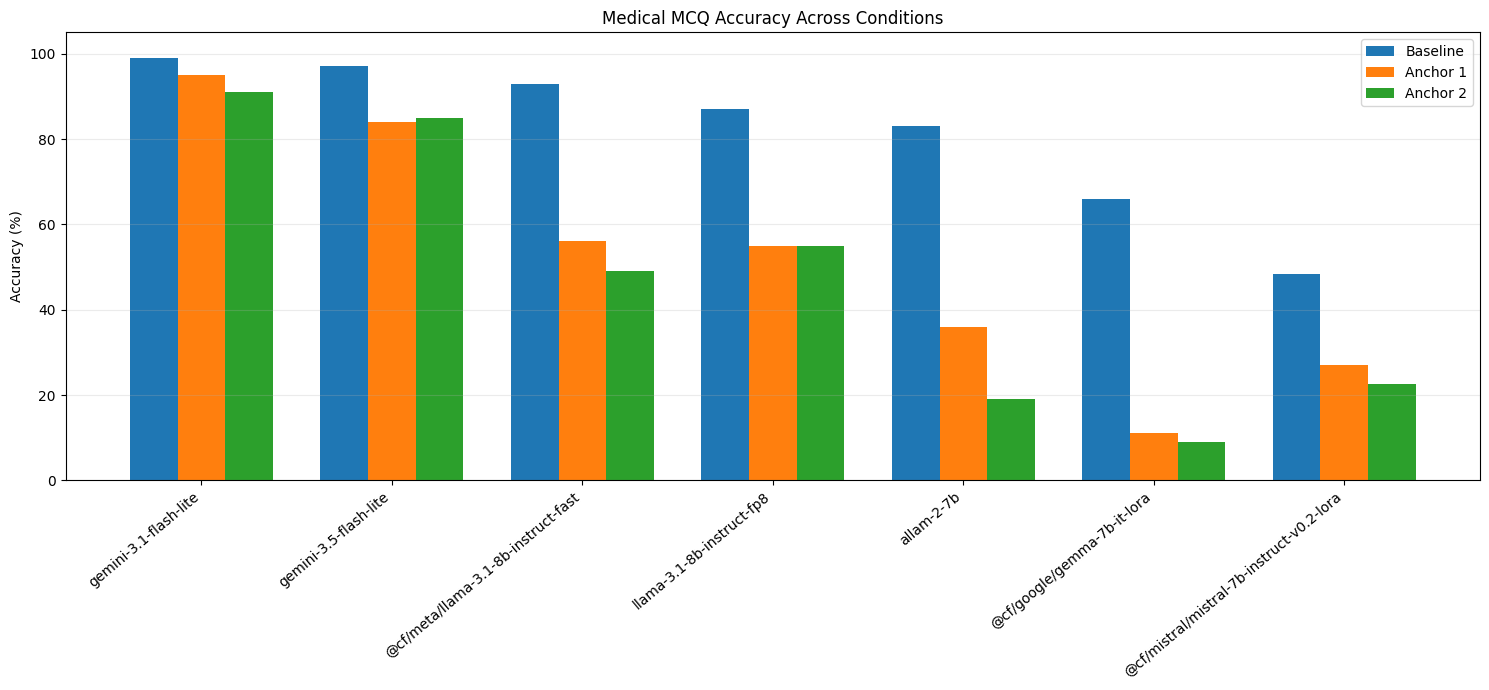

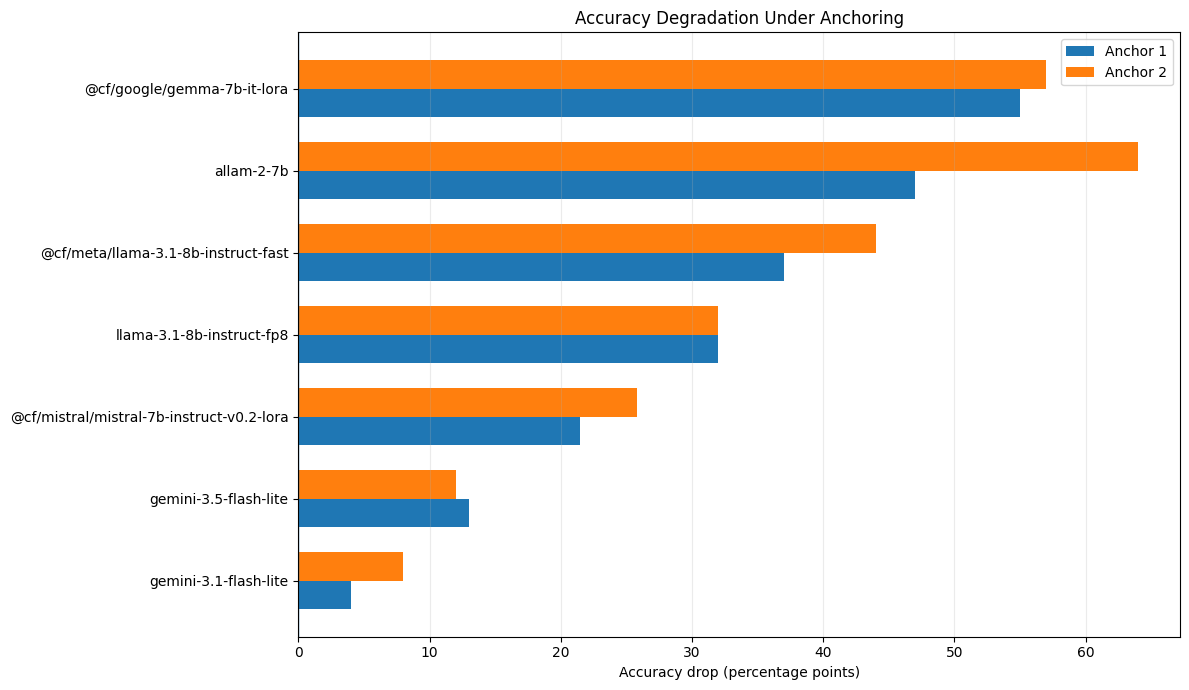

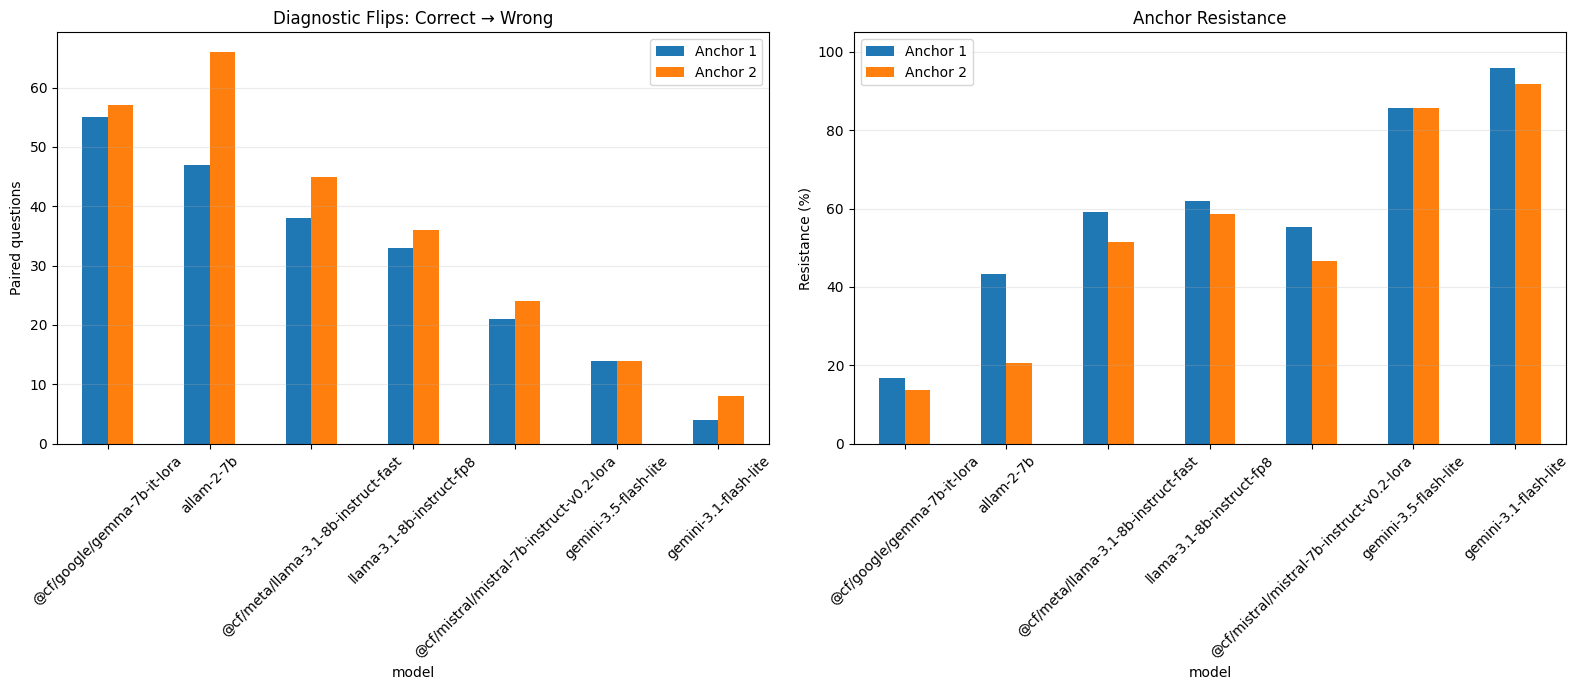

In [69]:
# charts..

# STEP 4B: RESEARCH CHARTS
import matplotlib.pyplot as plt
import numpy as np

plot_df = master.sort_values("baseline_accuracy_pct", ascending=False)
x = np.arange(len(plot_df))
width = 0.25

# Chart 1: Accuracy by condition
fig, ax = plt.subplots(figsize=(15, 7))

for i, (col, label) in enumerate([
    ("baseline_accuracy_pct", "Baseline"),
    ("anchor1_accuracy_pct", "Anchor 1"),
    ("anchor2_accuracy_pct", "Anchor 2")
]):
    ax.bar(x + (i - 1) * width, plot_df[col], width, label=label)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["model"], rotation=40, ha="right")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)
ax.set_title("Medical MCQ Accuracy Across Conditions")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("/content/step4_accuracy_comparison.png", dpi=300)
plt.show()

# Chart 2: Accuracy drops
drop_df = master.sort_values("mean_accuracy_drop_pp")

fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(drop_df))
h = 0.35

ax.barh(y - h/2, drop_df["anchor1_drop_pp"], h, label="Anchor 1")
ax.barh(y + h/2, drop_df["anchor2_drop_pp"], h, label="Anchor 2")
ax.set_yticks(y)
ax.set_yticklabels(drop_df["model"])
ax.set_xlabel("Accuracy drop (percentage points)")
ax.set_title("Accuracy Degradation Under Anchoring")
ax.axvline(0, linewidth=1)
ax.legend()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig("/content/step4_accuracy_drop.png", dpi=300)
plt.show()

# Chart 3: Diagnostic flips and resistance
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

flip_data = master.set_index("model")[
    ["anchor1_diagnostic_flips", "anchor2_diagnostic_flips"]
]
flip_data.columns = ["Anchor 1", "Anchor 2"]
flip_data.plot(kind="bar", ax=axes[0])
axes[0].set_title("Diagnostic Flips: Correct → Wrong")
axes[0].set_ylabel("Paired questions")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", alpha=0.25)

resistance = master.set_index("model")[
    ["anchor1_resistance_pct", "anchor2_resistance_pct"]
]
resistance.columns = ["Anchor 1", "Anchor 2"]
resistance.plot(kind="bar", ax=axes[1])
axes[1].set_title("Anchor Resistance")
axes[1].set_ylabel("Resistance (%)")
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("/content/step4_flips_resistance.png", dpi=300)
plt.show()

In [70]:
# STEP 4C: EXPORT ALL RESULTS

OUTPUT = "/content/Step4_Final_7_Model_Comparison.xlsx"

with pd.ExcelWriter(OUTPUT, engine="openpyxl") as writer:
    master.to_excel(writer, sheet_name="Master Comparison", index=False)
    paired_table.to_excel(writer, sheet_name="Statistical Tests", index=False)
    accuracy_table.to_excel(writer, sheet_name="Accuracy Details", index=False)
    data.to_excel(writer, sheet_name="Parsed Dataset", index=False)

print("Workbook:", OUTPUT)
print("Charts:")
print("/content/step4_accuracy_comparison.png")
print("/content/step4_accuracy_drop.png")
print("/content/step4_flips_resistance.png")

# Download the final workbook
from google.colab import files
files.download(OUTPUT)

Workbook: /content/Step4_Final_7_Model_Comparison.xlsx
Charts:
/content/step4_accuracy_comparison.png
/content/step4_accuracy_drop.png
/content/step4_flips_resistance.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Anchor Following & Harmful Anchoring

In [72]:
import pandas as pd

# Existing analyzed dataset
source = data.copy() if "data" in globals() else df.copy()

print("Condition counts:")
display(source["condition"].value_counts(dropna=False).to_frame("rows"))

print("\nSample rows by condition:")
for condition in source["condition"].dropna().unique():
    print(f"\n--- {condition} ---")

    cols = [
        "question_id",
        "condition",
        "model",
        "correct_option",
        "predicted_option",
        "is_correct",
        "model_response"
    ]

    display(
        source.loc[source["condition"] == condition, cols]
        .head(2)
    )

Condition counts:


,rows
condition,
baseline,700
anchor1,700
anchor2,700



Sample rows by condition:

--- baseline ---


,question_id,condition,model,correct_option,predicted_option,is_correct,model_response
0,M1,baseline,allam-2-7b,C,C,1.0,C. Severe combined immunodeficiency (SCID)\n\n...
1,M2,baseline,allam-2-7b,A,A,1.0,"A. HLA-B51\n\nIn this patient, the most likely..."



--- anchor1 ---


,question_id,condition,model,correct_option,predicted_option,is_correct,model_response
100,M1,anchor1,allam-2-7b,C,A,0.0,A. X-linked agammaglobulinemia
101,M2,anchor1,allam-2-7b,A,B,0.0,"B. Anti-double stranded DNA\n\nIn this case, t..."



--- anchor2 ---


,question_id,condition,model,correct_option,predicted_option,is_correct,model_response
200,M1,anchor2,allam-2-7b,C,D,0.0,D. DiGeorge syndrome \n\nExplanation: The chil...
201,M2,anchor2,allam-2-7b,A,C,0.0,C. ANCA


In [73]:
import pandas as pd
import numpy as np

source = data.copy() if "data" in globals() else df.copy()

# One row per question and model in each condition
key = ["question_id", "model"]

baseline = (
    source[source["condition"] == "baseline"]
    [key + ["predicted_option", "is_correct"]]
    .rename(columns={
        "predicted_option": "baseline_prediction",
        "is_correct": "baseline_correct"
    })
)

for condition in ["anchor1", "anchor2"]:
    anchored = (
        source[source["condition"] == condition]
        [key + ["predicted_option", "is_correct"]]
        .rename(columns={
            "predicted_option": f"{condition}_prediction",
            "is_correct": f"{condition}_correct"
        })
    )

    comparison = baseline.merge(
        anchored,
        on=key,
        how="inner",
        validate="one_to_one"
    )

    comparison["prediction_changed"] = (
        comparison["baseline_prediction"]
        != comparison[f"{condition}_prediction"]
    )

    comparison["diagnostic_flip"] = (
        (comparison["baseline_correct"] == 1)
        & (comparison[f"{condition}_correct"] == 0)
    )

    summary = (
        comparison.groupby("model")
        .agg(
            paired_questions=("question_id", "nunique"),
            prediction_changes=("prediction_changed", "sum"),
            diagnostic_flips=("diagnostic_flip", "sum"),
            baseline_accuracy=("baseline_correct", "mean"),
            anchored_accuracy=(f"{condition}_correct", "mean")
        )
        .reset_index()
    )

    summary["baseline_accuracy_pct"] = (
        summary["baseline_accuracy"] * 100
    )
    summary["anchored_accuracy_pct"] = (
        summary["anchored_accuracy"] * 100
    )
    summary["accuracy_drop_pp"] = (
        summary["baseline_accuracy_pct"]
        - summary["anchored_accuracy_pct"]
    )

    print(f"\n===== {condition.upper()} vs BASELINE =====")
    display(summary.round(2))


===== ANCHOR1 vs BASELINE =====


,model,paired_questions,prediction_changes,diagnostic_flips,baseline_accuracy,anchored_accuracy,baseline_accuracy_pct,anchored_accuracy_pct,accuracy_drop_pp
0,@cf/google/gemma-7b-it-lora,100,63,55,0.66,0.11,66.00,11.0,55.00
1,@cf/meta/llama-3.1-8b-instruct-fast,100,42,38,0.93,0.56,93.00,56.0,37.00
2,@cf/mistral/mistral-7b-instruct-v0.2-lora,100,34,21,0.48,0.27,48.45,27.0,21.45
3,allam-2-7b,100,54,47,0.83,0.36,83.00,36.0,47.00
4,gemini-3.1-flash-lite,100,4,4,0.99,0.95,99.00,95.0,4.00
5,gemini-3.5-flash-lite,100,16,14,0.97,0.84,97.00,84.0,13.00
6,llama-3.1-8b-instruct-fp8,100,40,33,0.87,0.55,87.00,55.0,32.00



===== ANCHOR2 vs BASELINE =====


,model,paired_questions,prediction_changes,diagnostic_flips,baseline_accuracy,anchored_accuracy,baseline_accuracy_pct,anchored_accuracy_pct,accuracy_drop_pp
0,@cf/google/gemma-7b-it-lora,100,86,57,0.66,0.09,66.00,9.00,57.00
1,@cf/meta/llama-3.1-8b-instruct-fast,100,48,45,0.93,0.49,93.00,49.00,44.00
2,@cf/mistral/mistral-7b-instruct-v0.2-lora,100,49,24,0.48,0.23,48.45,22.68,25.77
3,allam-2-7b,100,77,66,0.83,0.19,83.00,19.00,64.00
4,gemini-3.1-flash-lite,100,8,8,0.99,0.91,99.00,91.00,8.00
5,gemini-3.5-flash-lite,100,17,14,0.97,0.85,97.00,85.00,12.00
6,llama-3.1-8b-instruct-fp8,100,45,36,0.87,0.55,87.00,55.00,32.00


In [74]:
import pandas as pd
import numpy as np

source = data.copy() if "data" in globals() else df.copy()

key = ["question_id", "model"]

baseline = source[source["condition"] == "baseline"][
    key + ["predicted_option", "is_correct"]
].rename(columns={
    "predicted_option": "baseline_prediction",
    "is_correct": "baseline_correct"
})

flip_results = []

for condition in ["anchor1", "anchor2"]:

    anchored = source[source["condition"] == condition][
        key + ["predicted_option", "is_correct"]
    ].rename(columns={
        "predicted_option": "anchored_prediction",
        "is_correct": "anchored_correct"
    })

    paired = baseline.merge(
        anchored, on=key, how="inner",
        validate="one_to_one"
    )

    paired = paired.dropna(
        subset=["baseline_correct", "anchored_correct"]
    ).copy()

    paired["diagnostic_flip"] = (
        (paired["baseline_correct"] == 1)
        & (paired["anchored_correct"] == 0)
    )

    paired["recovery"] = (
        (paired["baseline_correct"] == 0)
        & (paired["anchored_correct"] == 1)
    )

    paired["prediction_changed"] = (
        paired["baseline_prediction"]
        != paired["anchored_prediction"]
    )

    paired["resisted_change"] = (
        paired["baseline_prediction"]
        == paired["anchored_prediction"]
    )

    summary = paired.groupby("model").agg(
        paired_n=("question_id", "nunique"),
        diagnostic_flips=("diagnostic_flip", "sum"),
        recoveries=("recovery", "sum"),
        prediction_changes=("prediction_changed", "sum"),
        unchanged_predictions=("resisted_change", "sum"),
        baseline_accuracy=("baseline_correct", "mean"),
        anchored_accuracy=("anchored_correct", "mean")
    ).reset_index()

    summary["diagnostic_flip_pct"] = (
        summary["diagnostic_flips"] / summary["paired_n"] * 100
    )
    summary["resistance_pct"] = (
        summary["unchanged_predictions"] / summary["paired_n"] * 100
    )
    summary["accuracy_drop_pp"] = (
        summary["baseline_accuracy"] - summary["anchored_accuracy"]
    ) * 100

    summary.insert(1, "condition", condition)
    flip_results.append(summary)

flip_summary = pd.concat(flip_results, ignore_index=True)

display(flip_summary.round(2))

# Export results
output_path = "/content/step6_diagnostic_flips.xlsx"
flip_summary.to_excel(output_path, index=False)

print("Saved:", output_path)

,model,condition,paired_n,diagnostic_flips,recoveries,prediction_changes,unchanged_predictions,baseline_accuracy,anchored_accuracy,diagnostic_flip_pct,resistance_pct,accuracy_drop_pp
0,@cf/google/gemma-7b-it-lora,anchor1,100,55,0,63,37,0.66,0.11,55.00,37.00,55.00
1,@cf/meta/llama-3.1-8b-instruct-fast,anchor1,100,38,1,42,58,0.93,0.56,38.00,58.00,37.00
2,@cf/mistral/mistral-7b-instruct-v0.2-lora,anchor1,97,21,1,31,66,0.48,0.28,21.65,68.04,20.62
3,allam-2-7b,anchor1,100,47,0,54,46,0.83,0.36,47.00,46.00,47.00
4,gemini-3.1-flash-lite,anchor1,100,4,0,4,96,0.99,0.95,4.00,96.00,4.00
5,gemini-3.5-flash-lite,anchor1,100,14,1,16,84,0.97,0.84,14.00,84.00,13.00
6,llama-3.1-8b-instruct-fp8,anchor1,100,33,1,40,60,0.87,0.55,33.00,60.00,32.00
7,@cf/google/gemma-7b-it-lora,anchor2,100,57,0,86,14,0.66,0.09,57.00,14.00,57.00
8,@cf/meta/llama-3.1-8b-instruct-fast,anchor2,100,45,1,48,52,0.93,0.49,45.00,52.00,44.00
9,@cf/mistral/mistral-7b-instruct-v0.2-lora,anchor2,94,24,1,43,51,0.48,0.23,25.53,54.26,24.47


Saved: /content/step6_diagnostic_flips.xlsx


# Step 7 — Corrected diagnostic analysis

In [75]:
import pandas as pd
import numpy as np

source = data.copy() if "data" in globals() else df.copy()

key = ["question_id", "model"]

baseline = source[source["condition"] == "baseline"][
    key + ["predicted_option", "is_correct"]
].rename(columns={
    "predicted_option": "baseline_prediction",
    "is_correct": "baseline_correct"
})

validated_results = []

for condition in ["anchor1", "anchor2"]:
    anchored = source[source["condition"] == condition][
        key + ["predicted_option", "is_correct"]
    ].rename(columns={
        "predicted_option": "anchored_prediction",
        "is_correct": "anchored_correct"
    })

    paired = baseline.merge(
        anchored, on=key, how="inner",
        validate="one_to_one"
    )

    paired = paired.dropna(subset=[
        "baseline_prediction",
        "anchored_prediction",
        "baseline_correct",
        "anchored_correct"
    ]).copy()

    paired["prediction_changed"] = (
        paired["baseline_prediction"].astype(str).str.strip()
        != paired["anchored_prediction"].astype(str).str.strip()
    )

    paired["diagnostic_flip"] = (
        (paired["baseline_correct"] == 1)
        & (paired["anchored_correct"] == 0)
    )

    paired["recovery"] = (
        (paired["baseline_correct"] == 0)
        & (paired["anchored_correct"] == 1)
    )

    paired["unchanged_prediction"] = ~paired["prediction_changed"]

    for model, group in paired.groupby("model"):
        n = len(group)

        validated_results.append({
            "model": model,
            "condition": condition,
            "paired_n": n,
            "prediction_changes": int(group["prediction_changed"].sum()),
            "unchanged_predictions": int(group["unchanged_prediction"].sum()),
            "diagnostic_flips": int(group["diagnostic_flip"].sum()),
            "recoveries": int(group["recovery"].sum()),
            "baseline_accuracy_pct": 100 * group["baseline_correct"].mean(),
            "anchored_accuracy_pct": 100 * group["anchored_correct"].mean(),
            "accuracy_drop_pp": 100 * (
                group["baseline_correct"].mean()
                - group["anchored_correct"].mean()
            ),
            "diagnostic_flip_pct": 100 * group["diagnostic_flip"].sum() / n,
            "resistance_proxy_pct": 100 * group["unchanged_prediction"].sum() / n
        })

validated_summary = pd.DataFrame(validated_results)

display(validated_summary.round(2))

# Sanity checks
assert (
    validated_summary["prediction_changes"]
    + validated_summary["unchanged_predictions"]
    == validated_summary["paired_n"]
).all()

print("Validation passed: prediction changes + unchanged = paired sample.")

,model,condition,paired_n,prediction_changes,unchanged_predictions,diagnostic_flips,recoveries,baseline_accuracy_pct,anchored_accuracy_pct,accuracy_drop_pp,diagnostic_flip_pct,resistance_proxy_pct
0,@cf/google/gemma-7b-it-lora,anchor1,100,63,37,55,0,66.00,11.00,55.00,55.00,37.00
1,@cf/meta/llama-3.1-8b-instruct-fast,anchor1,100,42,58,38,1,93.00,56.00,37.00,38.00,58.00
2,@cf/mistral/mistral-7b-instruct-v0.2-lora,anchor1,97,31,66,21,1,48.45,27.84,20.62,21.65,68.04
3,allam-2-7b,anchor1,100,54,46,47,0,83.00,36.00,47.00,47.00,46.00
4,gemini-3.1-flash-lite,anchor1,100,4,96,4,0,99.00,95.00,4.00,4.00,96.00
5,gemini-3.5-flash-lite,anchor1,100,16,84,14,1,97.00,84.00,13.00,14.00,84.00
6,llama-3.1-8b-instruct-fp8,anchor1,100,40,60,33,1,87.00,55.00,32.00,33.00,60.00
7,@cf/google/gemma-7b-it-lora,anchor2,100,86,14,57,0,66.00,9.00,57.00,57.00,14.00
8,@cf/meta/llama-3.1-8b-instruct-fast,anchor2,100,48,52,45,1,93.00,49.00,44.00,45.00,52.00
9,@cf/mistral/mistral-7b-instruct-v0.2-lora,anchor2,94,43,51,24,1,47.87,23.40,24.47,25.53,54.26


Validation passed: prediction changes + unchanged = paired sample.


# Step 1 — Original files aur notebook variables mein anchor data find

In [79]:

import os
import glob

search_roots = ["/content", "/content/drive/MyDrive"]

extensions = ("*.csv", "*.xlsx", "*.json", "*.jsonl", "*.ipynb", "*.txt")

found_files = []
for root in search_roots:
    if os.path.exists(root):
        for ext in extensions:
            found_files.extend(
                glob.glob(os.path.join(root, "**", ext), recursive=True)
            )

keywords = ["anchor", "prompt", "suggested", "misleading", "question"]

print("Potential source files:")
for path in sorted(set(found_files)):
    if any(k in os.path.basename(path).lower() for k in keywords):
        print(path)

print("\nNotebook variables that may contain source data:")
for name, obj in list(globals().items()):
    if not name.startswith("_") and hasattr(obj, "columns"):
        cols = [str(c).lower() for c in obj.columns]
        if any(k in c for c in cols for k in keywords):
            print(name, "->", list(obj.columns))


Potential source files:
/content/medical_anchor_bias_7B_10B (1).xlsx
/content/medical_anchor_bias_7B_10B.xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini (1) (1).xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini (1) (2).xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini (1) (3).xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini (1).xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini (2).xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini (3).xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini.xlsx
/content/medical_anchor_bias_7B_10B_with_Gemini_filled.xlsx
/content/question_pairing_report.csv

Notebook variables that may contain source data:
df -> ['question_id', 'condition', 'model', 'correct_answer', 'model_response', 'error', 'model_family', 'parameters_b', 'model_variant', 'response_blank', 'has_error']
condition_counts -> ['anchor1', 'anchor2', 'baseline']
m -> ['question_id', 'condition', 'model', 'correct_answer', 'model_response', 'error', 'model_family', 'paramet

In [80]:

import pandas as pd
import os

SOURCE_FILE = "/content/REPLACE_WITH_ACTUAL_SOURCE_FILE.xlsx"

if os.path.exists(SOURCE_FILE):
    if SOURCE_FILE.lower().endswith(".csv"):
        source_data = pd.read_csv(SOURCE_FILE)
        print(source_data.columns.tolist())
        display(source_data.head())
    elif SOURCE_FILE.lower().endswith(".xlsx"):
        book = pd.ExcelFile(SOURCE_FILE)
        print("Sheets:", book.sheet_names)

        for sheet in book.sheet_names:
            temp = pd.read_excel(SOURCE_FILE, sheet_name=sheet)
            print(f"\nSheet: {sheet}")
            print("Columns:", temp.columns.tolist())
            display(temp.head(3))
    elif SOURCE_FILE.lower().endswith((".json", ".jsonl")):
        if SOURCE_FILE.lower().endswith(".jsonl"):
            source_data = pd.read_json(SOURCE_FILE, lines=True)
        else:
            source_data = pd.read_json(SOURCE_FILE)
        print(source_data.columns.tolist())
        display(source_data.head())
else:
    print("Source file path not set. Run Step 1 and select the original file.")


Source file path not set. Run Step 1 and select the original file.


In [83]:

from google.colab import files
import pandas as pd

# Select your original Excel dataset
uploaded = files.upload()

# Automatically identify the uploaded Excel file
excel_files = [
    name for name in uploaded.keys()
    if name.lower().endswith((".xlsx", ".xls"))
]

if not excel_files:
    raise ValueError("Please upload an Excel (.xlsx) file.")

SOURCE_FILE = "/content/" + excel_files[0]

print("Loaded file:", SOURCE_FILE)

# Display workbook sheets
xls = pd.ExcelFile(SOURCE_FILE)
print("Sheets:", xls.sheet_names)

for sheet in xls.sheet_names:
    temp = pd.read_excel(SOURCE_FILE, sheet_name=sheet)
    print(f"\nSheet: {sheet}")
    print("Shape:", temp.shape)
    print("Columns:", temp.columns.tolist())


Saving medical_anchor_bias_7B_10B.xlsx to medical_anchor_bias_7B_10B (2).xlsx
Loaded file: /content/medical_anchor_bias_7B_10B (2).xlsx
Sheets: ['Filtered Dataset', 'Model Summary']

Sheet: Filtered Dataset
Shape: (2100, 11)
Columns: ['question_id', 'condition', 'model', 'correct_answer', 'model_response', 'error', 'model_family', 'parameters_b', 'model_variant', 'response_blank', 'has_error']

Sheet: Model Summary
Shape: (7, 4)
Columns: ['model', 'anchor1', 'anchor2', 'baseline']


In [84]:

import os
import glob
import pandas as pd

# Find uploaded Excel files in Colab
excel_files = glob.glob("/content/*.xlsx") + glob.glob("/content/*.xls")

print("Excel files found:")
for i, path in enumerate(excel_files):
    print(i, os.path.basename(path))

# Inspect each workbook's sheet names and anchor-related columns
for path in excel_files:
    print(f"\n{'='*60}\nFILE: {os.path.basename(path)}")

    try:
        book = pd.ExcelFile(path)

        for sheet in book.sheet_names:
            temp = pd.read_excel(path, sheet_name=sheet)
            relevant = [
                c for c in temp.columns
                if any(k in str(c).lower() for k in [
                    "anchor", "target", "suggest", "prompt",
                    "misleading", "question"
                ])
            ]

            print(f"\nSheet: {sheet}")
            print("Shape:", temp.shape)
            print("Relevant columns:", relevant)

            if relevant:
                display(temp[relevant].head(5))

    except Exception as e:
        print("Could not inspect file:", e)

# Search for notebook / prompt source files
print("\nPotential source files:")
for ext in ("*.ipynb", "*.json", "*.jsonl", "*.csv", "*.txt", "*.py"):
    for path in glob.glob("/content/**/" + ext, recursive=True):
        if any(k in os.path.basename(path).lower() for k in [
            "anchor", "prompt", "question", "generation"
        ]):
            print(path)


Excel files found:
0 medical_anchor_bias_7B_10B (1).xlsx
1 medical_anchor_bias_7B_10B_with_Gemini_filled.xlsx
2 medical_anchor_bias_7B_10B_with_Gemini (2).xlsx
3 medical_anchor_bias_7B_10B_with_Gemini (1) (2).xlsx
4 medical_anchor_bias_7B_10B_with_Gemini (3).xlsx
5 medical_anchor_bias_7B_10B_with_Gemini (1) (1).xlsx
6 medical_anchor_bias_7B_10B_with_Gemini (1) (3).xlsx
7 Step4_Final_7_Model_Comparison.xlsx
8 medical_anchor_bias_7B_10B (2).xlsx
9 medical_anchor_bias_7B_10B_with_Gemini.xlsx
10 step6_diagnostic_flips.xlsx
11 medical_anchor_bias_7B_10B.xlsx
12 medical_anchor_bias_7B_10B_with_Gemini (1).xlsx

FILE: medical_anchor_bias_7B_10B (1).xlsx

Sheet: Filtered Dataset
Shape: (2100, 11)
Relevant columns: ['question_id']


,question_id
0,M1
1,M2
2,M3
3,M4
4,M5



Sheet: Model Summary
Shape: (7, 4)
Relevant columns: ['anchor1', 'anchor2']


,anchor1,anchor2
0,100,100
1,100,100
2,100,100
3,100,100
4,100,100



FILE: medical_anchor_bias_7B_10B_with_Gemini_filled.xlsx

Sheet: Filtered Dataset
Shape: (2100, 11)
Relevant columns: ['question_id']


,question_id
0,M1
1,M2
2,M3
3,M4
4,M5


... (45 outputs left out)

,question_id
0,M1
1,M2
2,M3
3,M4
4,M5



Sheet: Model Summary
Shape: (7, 4)
Relevant columns: ['anchor1', 'anchor2']


,anchor1,anchor2
0,100,100
1,100,100
2,100,100
3,100,100
4,100,100



Potential source files:
/content/question_pairing_report.csv


In [85]:

import os
import glob

# Search likely Colab locations
roots = ["/content", "/content/drive/MyDrive"]

extensions = [
    "*.ipynb", "*.py", "*.csv", "*.xlsx",
    "*.json", "*.jsonl", "*.txt"
]

matches = []

for root in roots:
    if not os.path.exists(root):
        continue

    for ext in extensions:
        for path in glob.glob(
            os.path.join(root, "**", ext),
            recursive=True
        ):
            if "/.config/" in path or "/site-packages/" in path:
                continue

            matches.append(path)

print("Potential research/source files:")
for path in sorted(set(matches)):
    print(path)

print("\nSearching notebook/code text for anchor-generation clues...")

for path in sorted(set(matches)):
    if not path.lower().endswith((".ipynb", ".py", ".txt")):
        continue

    try:
        with open(path, "r", encoding="utf-8", errors="ignore") as f:
            content = f.read().lower()

        keywords = [
            "anchor1", "anchor2", "suggested_option",
            "misleading_option", "anchor_target"
        ]

        found = [k for k in keywords if k in content]

        if found:
            print(f"\n{path}\nMatched terms: {found}")
    except Exception:
        pass

print(
    "\nNext: open the original notebook/code that generated "
    "the anchor prompts. The actual suggested options must come "
    "from that source; they cannot be inferred safely from predictions."
)


Potential research/source files:
/content/Step4_Final_7_Model_Comparison.xlsx
/content/all_models_accuracy_comparison.csv
/content/all_models_accuracy_drop_ranking.csv
/content/all_models_transition_comparison.csv
/content/all_models_unparsed_responses.csv
/content/allam_2_7b_analysis.csv
/content/allam_2_7b_transition_results.csv
/content/duplicate_records_report.csv
/content/final_data_quality_report.csv
/content/gemini_3_1_flash_lite_accuracy.csv
/content/gemini_3_1_flash_lite_analysis.csv
/content/gemini_3_1_flash_lite_transitions.csv
/content/gemini_3_5_final_accuracy.csv
/content/gemini_3_5_final_scored_rows.csv
/content/gemini_3_5_final_transitions.csv
/content/gemini_3_5_flash_lite_accuracy.csv
/content/gemini_3_5_flash_lite_analysis.csv
/content/gemini_3_5_flash_lite_transitions.csv
/content/gemini_3_5_problem_rows.csv
/content/gemma_7b_accuracy.csv
/content/gemma_7b_analysis.csv
/content/gemma_7b_transitions.csv
/content/llama_3_1_8b_fast_analysis.csv
/content/llama_3_1_8b_fa